# Explainable AI for Autonomous Vehicle Safety

## Project Overview
This project explores whether machine learning can help identify higher-risk autonomous vehicle safety events using historical disengagement and collision reports. The analysis uses data from the California DMV to examine patterns in autonomous vehicle disengagements, testing mileage, and reported collisions.

The goal is to build an initial classification model that can distinguish between disengagement and collision events and evaluate whether the available data contains useful patterns for identifying higher-risk safety events.

## Research Question
Can machine learning predict autonomous vehicle safety risk using historical disengagement and crash reports, and what factors contribute most to that risk?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Collection and Loading

The project uses three datasets from the California DMV: autonomous vehicle disengagement reports, autonomous mileage reports, and autonomous vehicle collision reports. These datasets provide information about disengagement events, testing mileage, manufacturers, and reported collisions.

In [2]:
disengagement_df = pd.read_csv("2024-Autonomous-Vehicle-Disengagement-Reports-CSV-1.csv",encoding="cp1252")
disengagement_df.head()

,Manufacturer,Permit Number,DATE,VIN NUMBER,VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No),DRIVER PRESENT\n(Yes or No),"DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)","DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)",DESCRIPTION OF FACTS CAUSING DISENGAGEMENT
0,aiMotive Inc.,AVT036,11/21/2024,4T1B21HK3KU514477,No,Yes,Test Driver,Street,Safety Driver disengaged autonomous mode to en...
1,aiMotive Inc.,AVT036,11/21/2024,4T1B21HK3KU514477,No,Yes,Test Driver,Street,Safety Driver disengaged autonomous mode due t...
2,aiMotive Inc.,AVT036,11/21/2024,4T1B21HK3KU514477,No,Yes,Test Driver,Freeway,Safety Driver disengaged autonomous mode to pe...
3,aiMotive Inc.,AVT036,10/2/2024,4T1B21HK6KU514747,No,Yes,Test Driver,Street,Safety Driver disengaged autonomous mode upon ...
4,aiMotive Inc.,AVT036,9/27/2024,4T1B21HK6KU514747,No,Yes,Test Driver,Highway,Safety Driver disengaged autonomous mode upon ...


In [3]:
mileage_df = pd.read_csv("2024-Autonomous-Mileage-Reports-CSV-2.csv")

mileage_df.head()

,Manufacturer,Permit Number,VIN NUMBER,Annual Total of Disengagements,DEC 2023,JAN 2024,FEB 2024,MAR 2024,APR 2024,MAY 2024,...,AUG 2024,SEP 2024,OCT 2024,NOV 2024,ANNUAL TOTAL,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21
0,aiMotive Inc.,AVT036,4T1B21HK3KU514477,75,485.01,526.06,601.46,142.53,27.51,0.19,...,0.0,64.20,11.19,22.22,"1,880.37",NaN,NaN,NaN,NaN,NaN
1,aiMotive Inc.,AVT036,1C4RJYB64P8914902,68,5.48,332.43,0.00,185.78,445.60,78.01,...,0.0,46.64,50.26,105.67,"1,249.98",NaN,NaN,NaN,NaN,NaN
2,aiMotive Inc.,AVT036,4T1B21HK6KU514747,45,170.80,71.61,0.00,0.00,15.34,0.00,...,0.0,205.33,151.10,0.00,614.18,NaN,NaN,NaN,NaN,NaN
3,Apollo,AVT015,3LN6L5LU2HR615153,0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.00,0.00,0,NaN,NaN,NaN,NaN,NaN
4,Apollo,AVT015,2C4RC1N77LR190366,0,0.00,0.00,0.00,0.00,0.00,0.00,...,0.0,0.00,0.00,0.00,0,NaN,NaN,NaN,NaN,NaN


In [4]:
collision_df = pd.read_excel("DMV AV Testing Collisions Data.xlsx")
collision_df.head()

,_Moving__V1_or_V2_or_Both_,_Stopped__V1_or_V2_,# of Vehicles involved,Backing,Broadside,City,Clear,Cloudy,Construction,County,...,V1_Vehicle Model,V1_Vehicle Year,V2 Damage _minor_ moderate_ severe_,V2_OPV Make,V2_OPV Model,V2_OPV Year,Wet,Wind,Year,Zip
0,V2,V1,2.0,NaN,V2,Palo Alto,NaN,NaN,NaN,Santa Clara,...,SQ5,2014,NaN,Honda,Civic,2012.0,NaN,NaN,2014,94303
1,Both,NaN,2.0,NaN,V2,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2012,NaN,Audi,S6,2015.0,NaN,NaN,2015,94040
2,NaN,NaN,2.0,NaN,NaN,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2011,NONE,BMW,3 Series,2011.0,NaN,NaN,2015,94040
3,NaN,V1,2.0,NaN,NaN,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2012,NONE,Toyota,Camry,2000.0,NaN,NaN,2015,94043
4,NaN,V1,2.0,NaN,NaN,Mountain View,NaN,NaN,NaN,Santa Clara,...,RX450H,2011,NONE,Ford,Expedition,2003.0,NaN,NaN,2015,94041


## Data Cleaning

Before performing the analysis, the datasets were examined for missing values, duplicate records, inconsistent data formats, and data type issues. Blank rows and completely empty columns were removed where appropriate. Date and numeric fields were converted to suitable formats, and inconsistent categorical values were standardized.

Potential duplicate disengagement records were reviewed but retained because the dataset does not contain a unique event identifier or event time that would confirm whether the records represent true duplicates or separate disengagement events.

In [5]:
print("Disengagement:", disengagement_df.shape)
print("Mileage:", mileage_df.shape)
print("Collision:", collision_df.shape)

Disengagement: (12607, 9)
Mileage: (2819, 22)
Collision: (983, 69)


In [6]:
print("DISENGAGEMENT")
print("Duplicate rows:", disengagement_df.duplicated().sum())
print(disengagement_df.isnull().sum())

print("\nMILEAGE")
print("Duplicate rows:", mileage_df.duplicated().sum())
print(mileage_df.isnull().sum())

print("\nCOLLISION")
print("Duplicate rows:", collision_df.duplicated().sum())
print(collision_df.isnull().sum())

DISENGAGEMENT
Duplicate rows: 11335
Manufacturer                                                                                        10834
Permit Number                                                                                       10834
DATE                                                                                                10834
VIN NUMBER                                                                                          10834
VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No)                                       10834
DRIVER PRESENT\n(Yes or No)                                                                         10834
DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)                 10834
DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)    10834
DESCRIPTION OF FACTS CAUSING DISENGAGEMENT                                                          10834
dtype: int

In [7]:
# Remove completely empty rows
disengagement_df = disengagement_df.dropna(how="all")

# Remove completely empty rows from mileage data
mileage_df = mileage_df.dropna(how="all")

# Remove completely empty columns from mileage data
mileage_df = mileage_df.dropna(axis=1, how="all")

# Check the new shapes
print("Disengagement:", disengagement_df.shape)
print("Mileage:", mileage_df.shape)
print("Collision:", collision_df.shape)

# Check duplicates again
print("\nDisengagement duplicates:", disengagement_df.duplicated().sum())
print("Mileage duplicates:", mileage_df.duplicated().sum())
print("Collision duplicates:", collision_df.duplicated().sum())

Disengagement: (1773, 9)
Mileage: (2819, 17)
Collision: (983, 69)

Disengagement duplicates: 502
Mileage duplicates: 0
Collision duplicates: 0


In [8]:
duplicate_rows = disengagement_df[disengagement_df.duplicated(keep=False)]

duplicate_rows.sort_values(by=["Manufacturer", "DATE"]).head(20)

,Manufacturer,Permit Number,DATE,VIN NUMBER,VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No),DRIVER PRESENT\n(Yes or No),"DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)","DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)",DESCRIPTION OF FACTS CAUSING DISENGAGEMENT
329,Apple Inc.,AVT030,1/24/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Interstate,The ADS incorrectly predicted the behavior of ...
330,Apple Inc.,AVT030,1/24/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Interstate,The ADS incorrectly predicted the behavior of ...
336,Apple Inc.,AVT030,1/24/2024,2T2BGMCA9GC007394,No,Yes,AV System,Freeway,The ADS initiated a disengagement due to a dia...
337,Apple Inc.,AVT030,1/24/2024,2T2BGMCA9GC007394,No,Yes,AV System,Freeway,The ADS initiated a disengagement due to a dia...
338,Apple Inc.,AVT030,1/24/2024,2T2BGMCA9GC007394,No,Yes,AV System,Freeway,The ADS initiated a disengagement due to a dia...
307,Apple Inc.,AVT030,1/26/2024,2T2BGMCA3GC007911,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
308,Apple Inc.,AVT030,1/26/2024,2T2BGMCA3GC007911,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
309,Apple Inc.,AVT030,1/26/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
310,Apple Inc.,AVT030,1/26/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...
311,Apple Inc.,AVT030,1/26/2024,2T2BGMCA0HC019225,No,Yes,Test Driver,Freeway,The ADS incorrectly predicted the behavior of ...


In [9]:
disengagement_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1773 entries, 0 to 1772
Data columns (total 9 columns):
 #   Column                                                                                          Non-Null Count  Dtype 
---  ------                                                                                          --------------  ----- 
 0   Manufacturer                                                                                    1773 non-null   object
 1   Permit Number                                                                                   1773 non-null   object
 2   DATE                                                                                            1773 non-null   object
 3   VIN NUMBER                                                                                      1773 non-null   object
 4   VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER
(Yes or No)                                    1773 non-null   object
 5   DRIVER PRESENT
(Yes or No)

In [10]:
mileage_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2819 entries, 0 to 2818
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Manufacturer                    2819 non-null   object 
 1   Permit Number                   2819 non-null   object 
 2   VIN NUMBER                      2819 non-null   object 
 3   Annual Total of Disengagements  2819 non-null   int64  
 4   DEC 2023                        2819 non-null   float64
 5   JAN 2024                        2819 non-null   float64
 6   FEB 2024                        2819 non-null   float64
 7   MAR 2024                        2819 non-null   float64
 8   APR 2024                        2817 non-null   float64
 9   MAY 2024                        2817 non-null   float64
 10  JUN 2024                        2817 non-null   float64
 11  JULY 2024                       2817 non-null   float64
 12  AUG 2024                        28

In [11]:
collision_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 983 entries, 0 to 982
Data columns (total 69 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   _Moving__V1_or_V2_or_Both_             661 non-null    object 
 1   _Stopped__V1_or_V2_                    445 non-null    object 
 2   # of Vehicles involved                 982 non-null    float64
 3   Backing                                98 non-null     object 
 4   Broadside                              84 non-null     object 
 5   City                                   983 non-null    object 
 6   Clear                                  773 non-null    object 
 7   Cloudy                                 94 non-null     object 
 8   Construction                           6 non-null      object 
 9   County                                 983 non-null    object 
 10  Dark_No Street Lights                  11 non-null     object 
 11  Dark_S

In [12]:
disengagement_df['DATE'] = pd.to_datetime(disengagement_df['DATE'],format='mixed')

In [13]:
disengagement_df['DATE'].dtype

dtype('<M8[ns]')

In [14]:
disengagement_df['DATE'].min(), disengagement_df['DATE'].max()

(Timestamp('2023-12-01 00:00:00'), Timestamp('2024-12-03 00:00:00'))

In [15]:
mileage_df['ANNUAL TOTAL'].head(10)

0    1,880.37
1    1,249.98
2      614.18
3           0
4           0
5           0
6           0
7           0
8         3.1
9      2000.7
Name: ANNUAL TOTAL, dtype: object

In [16]:
mileage_df['ANNUAL TOTAL'] = mileage_df['ANNUAL TOTAL'].str.replace(',', '')
mileage_df['ANNUAL TOTAL'] = pd.to_numeric(mileage_df['ANNUAL TOTAL'])

In [17]:
mileage_df['ANNUAL TOTAL'].dtype

dtype('float64')

In [18]:
mileage_df[mileage_df.isnull().any(axis=1)]

,Manufacturer,Permit Number,VIN NUMBER,Annual Total of Disengagements,DEC 2023,JAN 2024,FEB 2024,MAR 2024,APR 2024,MAY 2024,JUN 2024,JULY 2024,AUG 2024,SEP 2024,OCT 2024,NOV 2024,ANNUAL TOTAL
120,BOSCH,AVT006,WDD2221591A470497,4,0.00,19.96,0.0,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,19.96
121,BOSCH,AVT006,WDD2221591A470796,73,34.98,57.89,46.4,4.98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,144.25


## Exploratory Data Analysis

Exploratory data analysis was performed to understand patterns in the disengagement, mileage, and collision datasets. The analysis examines disengagements across manufacturers, locations, initiators, and time periods. Autonomous mileage is also considered to provide context for disengagement counts.

The collision data is explored to understand manufacturer patterns, injury reports, common collision types, vehicle operating modes, and changes in reported collisions over time.

In [19]:
disengagement_df['Manufacturer'].value_counts()

Manufacturer
Ghost Autonomy Inc.                                         351
Motional AD Inc.                                            320
Apple Inc.                                                  285
Waymo LLC                                                   244
aiMotive Inc.                                               188
IMAGRY                                                      136
NURO, INC.                                                  103
BOSCH                                                        77
Zoox, Inc.                                                   34
Valeo North America Inc.                                     12
Nissan North America. INC DBA NATC-SV                        11
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
PONY.AI, INC.                                                 3
Weride Corp                                                   3
Cruise LLC                                                    1
Gatik AI, Inc.             

### Disengagement Analysis

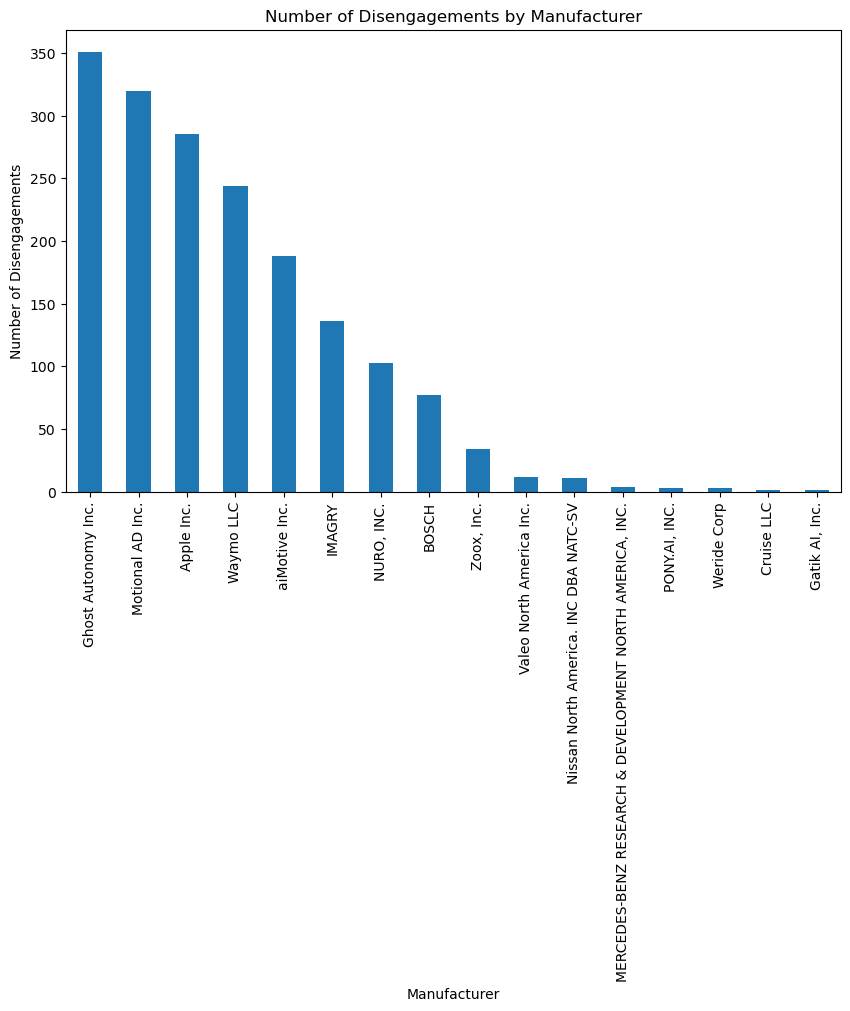

In [20]:
plt.figure(figsize=(10, 6))

disengagement_df['Manufacturer'].value_counts().plot(kind='bar')

plt.title('Number of Disengagements by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=90)

plt.show()

Observation: The number of reported disengagements varies across the companies participating in autonomous vehicle testing. Ghost Autonomy, Motional AD, Apple, and Waymo have the highest number of reported disengagement events in this dataset. However, these numbers should not be directly used to compare safety because each company may have completed a different amount of autonomous testing and mileage.

In [21]:
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'].value_counts()

DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)
Street              949
Highway             373
Freeway             248
Interstate          178
Urban                12
STREET               11
Parking Facility      2
Name: count, dtype: int64

In [22]:
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'] = \
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'].str.title()

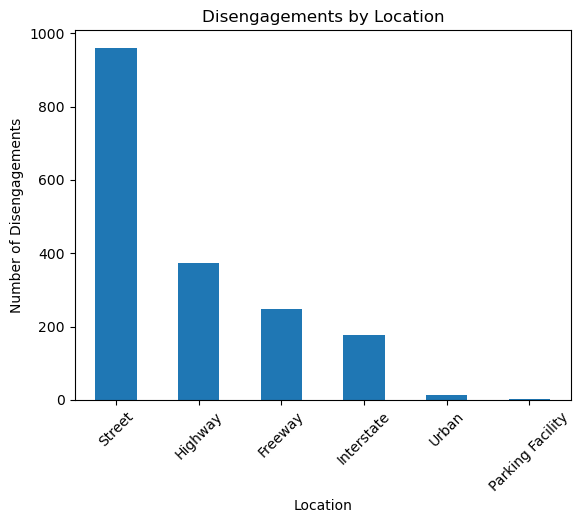

In [23]:
disengagement_df['DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)'].value_counts().plot(kind='bar')

plt.title('Disengagements by Location')
plt.xlabel('Location')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=45)

plt.show()

In [24]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'] = \
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].str.title()

In [25]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].value_counts()

DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)
Test Driver    1606
Av System       164
Operator          3
Name: count, dtype: int64

In [26]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'] = \
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].replace('Av System', 'AV System')

In [27]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].value_counts()

DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)
Test Driver    1606
AV System       164
Operator          3
Name: count, dtype: int64

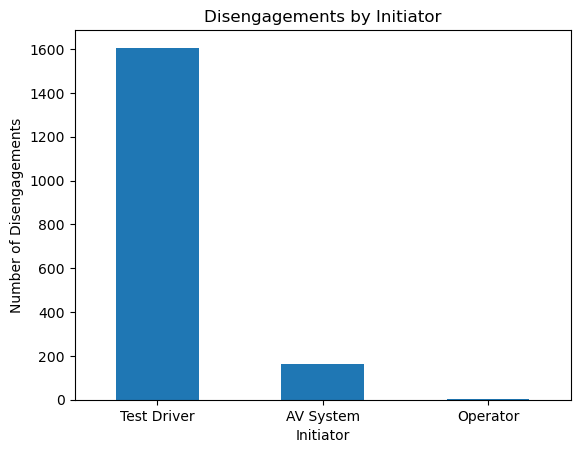

In [28]:
disengagement_df['DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)'].value_counts().plot(kind='bar')

plt.title('Disengagements by Initiator')
plt.xlabel('Initiator')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=0)

plt.show()

In [29]:
disengagement_df['Month'] = disengagement_df['DATE'].dt.to_period('M')
disengagement_df['Month'].value_counts().sort_index()

Month
2023-12    316
2024-01    429
2024-02    287
2024-03    148
2024-04    235
2024-05    113
2024-06     43
2024-07     20
2024-08     34
2024-09     63
2024-10     52
2024-11     32
2024-12      1
Freq: M, Name: count, dtype: int64

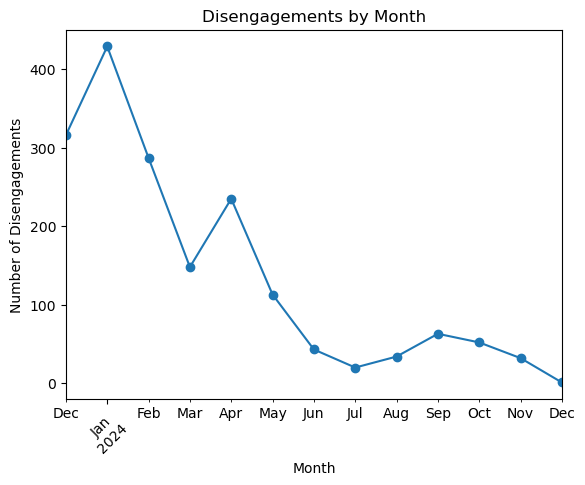

In [30]:
monthly_disengagements = disengagement_df['Month'].value_counts().sort_index()

monthly_disengagements.plot(kind='line', marker='o')

plt.title('Disengagements by Month')
plt.xlabel('Month')
plt.ylabel('Number of Disengagements')
plt.xticks(rotation=45)

plt.show()

### Mileage and Disengagement Rate Analysis

In [31]:
mileage_by_manufacturer = mileage_df.groupby('Manufacturer')['ANNUAL TOTAL'].sum()

mileage_by_manufacturer.sort_values(ascending=False)

Manufacturer
Waymo LLC                                                   2.389565e+06
Zoox, Inc.                                                  9.518710e+05
NURO, INC.                                                  2.105444e+05
Apple Inc.                                                  1.529237e+05
Weride Corp                                                 6.019174e+04
PONY.AI, INC.                                               5.155558e+04
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.    4.508121e+04
Motional AD Inc.                                            1.408350e+04
Ghost Autonomy Inc.                                         1.313823e+04
Cruise LLC                                                  8.008010e+03
AutoX Technologies, Inc.                                    7.459000e+03
aiMotive Inc.                                               3.744530e+03
Nissan North America. INC DBA NATC-SV                       2.153000e+03
IMAGRY                                

In [32]:
disengagement_counts = disengagement_df.groupby('Manufacturer').size()

disengagement_counts

Manufacturer
Apple Inc.                                                  285
BOSCH                                                        77
Cruise LLC                                                    1
Gatik AI, Inc.                                                1
Ghost Autonomy Inc.                                         351
IMAGRY                                                      136
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
Motional AD Inc.                                            320
NURO, INC.                                                  103
Nissan North America. INC DBA NATC-SV                        11
PONY.AI, INC.                                                 3
Valeo North America Inc.                                     12
Waymo LLC                                                   244
Weride Corp                                                   3
Zoox, Inc.                                                   34
aiMotive Inc.              

In [33]:
manufacturer_data = pd.concat([disengagement_counts, mileage_by_manufacturer],axis=1)
manufacturer_data.columns = ['Disengagements', 'Miles']
manufacturer_data

,Disengagements,Miles
Manufacturer,,
Apple Inc.,285.0,1.529237e+05
BOSCH,77.0,1.642100e+02
Cruise LLC,1.0,8.008010e+03
"Gatik AI, Inc.",1.0,7.260000e+02
Ghost Autonomy Inc.,351.0,1.313823e+04
IMAGRY,136.0,8.562000e+02
"MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.",4.0,4.508121e+04
Motional AD Inc.,320.0,1.408350e+04
"NURO, INC.",103.0,2.105444e+05


In [34]:
manufacturer_data = manufacturer_data.dropna().copy()
manufacturer_data['Disengagements_per_1000_miles'] = (manufacturer_data['Disengagements'] / manufacturer_data['Miles']) * 1000
manufacturer_data.sort_values('Disengagements_per_1000_miles',ascending=False)

,Disengagements,Miles,Disengagements_per_1000_miles
Manufacturer,,,
BOSCH,77.0,1.642100e+02,468.911759
Valeo North America Inc.,12.0,3.600000e+01,333.333333
IMAGRY,136.0,8.562000e+02,158.841392
aiMotive Inc.,188.0,3.744530e+03,50.206568
Ghost Autonomy Inc.,351.0,1.313823e+04,26.715927
Motional AD Inc.,320.0,1.408350e+04,22.721625
Nissan North America. INC DBA NATC-SV,11.0,2.153000e+03,5.109150
Apple Inc.,285.0,1.529237e+05,1.863674
"Gatik AI, Inc.",1.0,7.260000e+02,1.377410


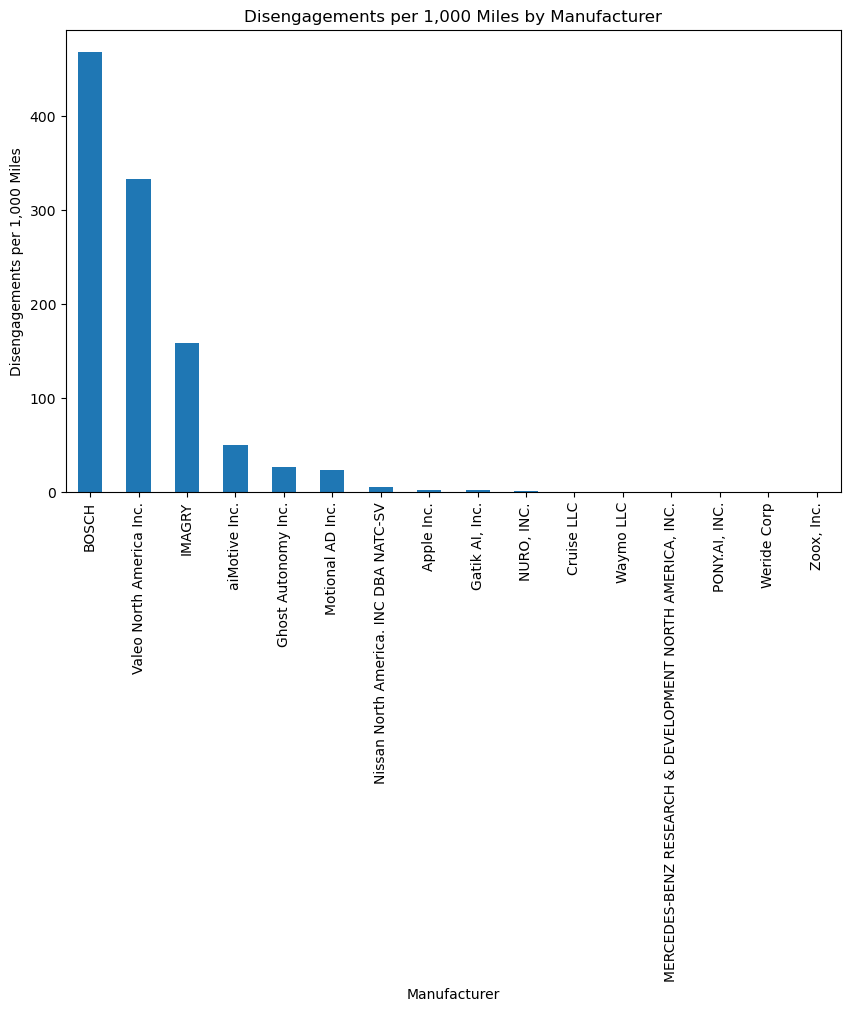

In [35]:
manufacturer_data['Disengagements_per_1000_miles'].sort_values(ascending=False).plot(kind='bar', figsize=(10, 6))
plt.title('Disengagements per 1,000 Miles by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Disengagements per 1,000 Miles')
plt.xticks(rotation=90)
plt.show()

Observation: Disengagement rates vary significantly across manufacturers after adjusting for autonomous miles driven. Some manufacturers, such as BOSCH and Valeo, show very high rates because they reported relatively low testing mileage. Therefore, these rates should be interpreted carefully and should not be considered a direct measure of vehicle safety.

### Collision Analysis

In [36]:
collision_df['V1_Manufacturer'] = (collision_df['V1_Manufacturer'].str.strip().str.upper())
collision_df['V1_Manufacturer'].value_counts()

V1_Manufacturer
WAYMO LLC                            438
ZOOX INC                             167
CRUISE LLC                           138
GM CRUISE                            100
APPLE INC                             23
GOOGLE                                21
PONY.AI                               15
WERIDE CORP DBA WERIDE AI             12
NURO, INC                             10
MERC BENZ                              9
LYFT, INC                              8
AURORA INNOVATION                      4
WAYMO                                  4
ARGO AI, LLC                           4
GHOST AUTONOMY INC                     3
APOLLO AUTONOMOUS DRIVING USA LLC      3
WERIDE CORP                            2
MERCEDES-BENZ                          2
UATC, LLC (UBER)                       2
WOVEN BY TOYOTA                        1
MAY MOBILITY                           1
BEEP INC                               1
AUTOX TECHNOLOGIES INC                 1
OHMIO, INC                             1


In [37]:
collision_df['V1_Manufacturer'] = collision_df['V1_Manufacturer'].replace({
    'WAYMO': 'WAYMO LLC',
    
    'ZOOX': 'ZOOX INC',
    
    'GM CRUISE': 'CRUISE LLC',
    'CRUISE': 'CRUISE LLC',
    'CRUISE AUTOMATION': 'CRUISE LLC',
    
    'WERIDE CORP': 'WERIDE CORP DBA WERIDE AI',
    
    'MERC BENZ': 'MERCEDES-BENZ',
    
    'AIMOTIVE INC': 'AIMOTIVE',
    
    'MOTIONAL': 'MOTIONAL AD INC'
})

collision_df['V1_Manufacturer'].value_counts()

V1_Manufacturer
WAYMO LLC                            442
CRUISE LLC                           240
ZOOX INC                             168
APPLE INC                             23
GOOGLE                                21
PONY.AI                               15
WERIDE CORP DBA WERIDE AI             14
MERCEDES-BENZ                         11
NURO, INC                             10
LYFT, INC                              8
ARGO AI, LLC                           4
AURORA INNOVATION                      4
APOLLO AUTONOMOUS DRIVING USA LLC      3
GHOST AUTONOMY INC                     3
UATC, LLC (UBER)                       2
WOVEN BY TOYOTA                        1
MAY MOBILITY                           1
AUTOX TECHNOLOGIES INC                 1
BEEP INC                               1
OHMIO, INC                             1
DELPHI                                 1
AIMOTIVE                               1
WOVEN PLANET NORTH AMERICA, INC        1
MOTIONAL AD INC                        1


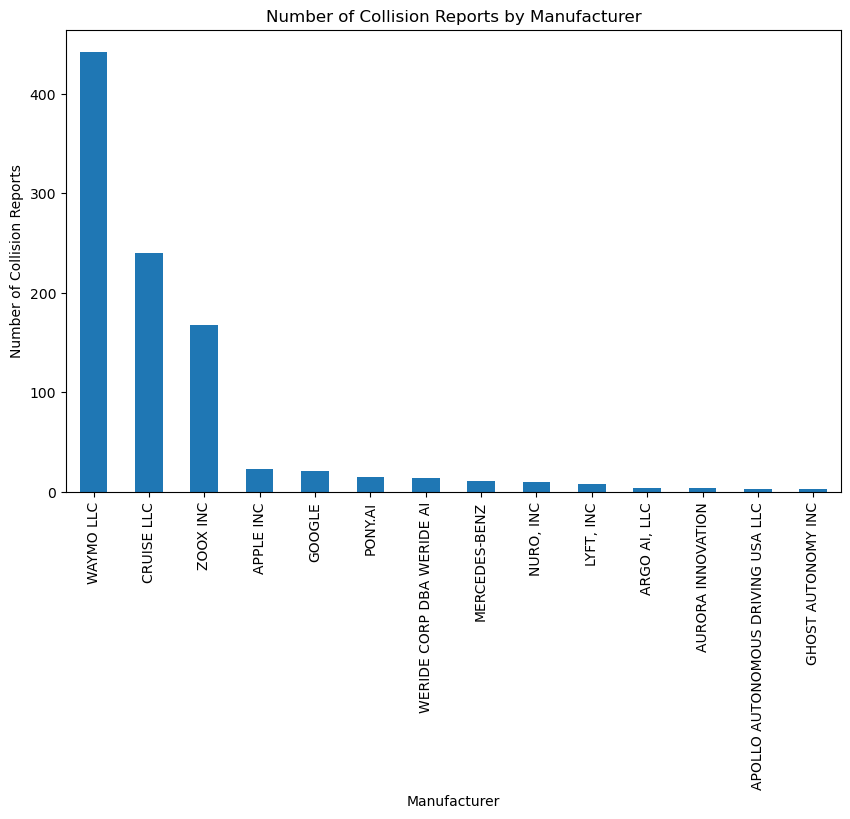

In [38]:
collision_counts = collision_df['V1_Manufacturer'].value_counts()
collision_counts[collision_counts >= 3].plot(kind='bar',figsize=(10, 6))

plt.title('Number of Collision Reports by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=90)

plt.show()

Observation: Waymo, Cruise, and Zoox have the highest number of collision reports in the dataset. However, collision counts alone should not be interpreted as a direct measure of safety because manufacturers may differ in testing mileage, number of vehicles, and years of operation.

In [39]:
collision_df['Injury'].value_counts(dropna=False)

Injury
NaN    878
X      105
Name: count, dtype: int64

In [40]:
collision_df['Injury_Status'] = collision_df['Injury'].apply(lambda x: 'Yes' if x == 'X' else 'No')
collision_df['Injury_Status'].value_counts()

Injury_Status
No     878
Yes    105
Name: count, dtype: int64

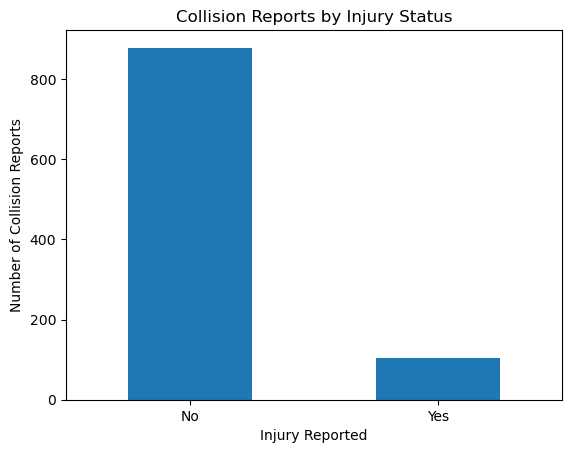

In [41]:
collision_df['Injury_Status'].value_counts().plot(kind='bar')

plt.title('Collision Reports by Injury Status')
plt.xlabel('Injury Reported')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=0)

plt.show()

In [42]:
collision_df['Property Damage'].value_counts(dropna=False)

Property Damage
NaN    974
X        9
Name: count, dtype: int64

In [43]:
collision_df['Property_Damage_Status'] = collision_df['Property Damage'].apply(lambda x: 'Yes' if x == 'X' else 'No')
collision_df['Property_Damage_Status'].value_counts()

Property_Damage_Status
No     974
Yes      9
Name: count, dtype: int64

In [44]:
collision_df['Rear_End'].value_counts(dropna=False)

Rear_End
NaN             531
V2              344
V1               87
Both             16
Bicyclist         3
V2&V3             1
Skateboarder      1
Name: count, dtype: int64

In [45]:
collision_df['Side_Swipe'].value_counts(dropna=False)

Side_Swipe
NaN          703
V2           142
Both          91
V1            45
V2 & V3        1
Bicyclist      1
Name: count, dtype: int64

In [46]:
collision_df['Broadside'].value_counts(dropna=False)

Broadside
NaN          899
V2            55
V1            21
Both           7
Bicyclist      1
Name: count, dtype: int64

In [47]:
collision_df['Rear_End_Flag'] = collision_df['Rear_End'].notna().astype(int)
collision_df['Side_Swipe_Flag'] = collision_df['Side_Swipe'].notna().astype(int)
collision_df['Broadside_Flag'] = collision_df['Broadside'].notna().astype(int)

collision_df[
    ['Rear_End_Flag', 'Side_Swipe_Flag', 'Broadside_Flag']].sum()

Rear_End_Flag      452
Side_Swipe_Flag    280
Broadside_Flag      84
dtype: int64

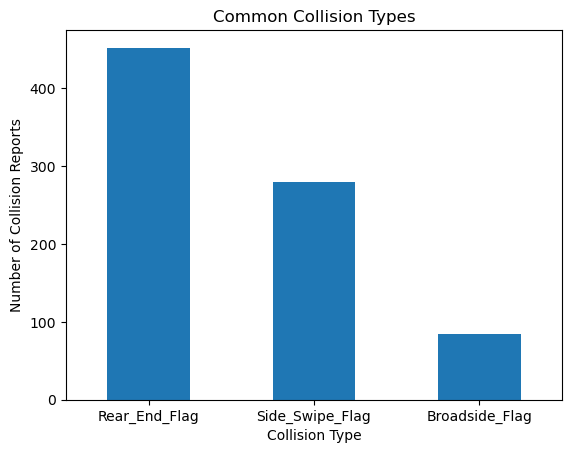

In [48]:
collision_types = collision_df[
    ['Rear_End_Flag', 'Side_Swipe_Flag', 'Broadside_Flag']
].sum()

collision_types.plot(kind='bar')

plt.title('Common Collision Types')
plt.xlabel('Collision Type')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=0)

plt.show()

Observation: Rear-end collisions are the most common among the three collision types examined, followed by side-swipe and broadside collisions. This suggests that rear-end interactions are a frequent type of reported collision in the dataset.

In [49]:
collision_df['V1_Mode_Reported_at_Time_of_Collision'].value_counts(dropna=False)

V1_Mode_Reported_at_Time_of_Collision
AM            578
CM            382
A              10
C               7
NaN             4
Autonomous      1
AV              1
Name: count, dtype: int64

In [50]:
collision_df['Operating_Mode'] = collision_df['V1_Mode_Reported_at_Time_of_Collision'].replace({
    'AM': 'Autonomous',
    'A': 'Autonomous',
    'Autonomous': 'Autonomous',
    'AV': 'Autonomous',
    'CM': 'Conventional',
    'C': 'Conventional'
})

collision_df['Operating_Mode'].value_counts(dropna=False)

Operating_Mode
Autonomous      590
Conventional    389
NaN               4
Name: count, dtype: int64

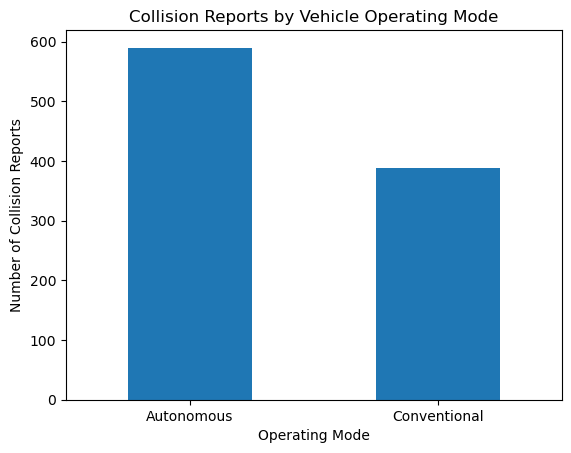

In [51]:
collision_df['Operating_Mode'].value_counts().plot(kind='bar')

plt.title('Collision Reports by Vehicle Operating Mode')
plt.xlabel('Operating Mode')
plt.ylabel('Number of Collision Reports')
plt.xticks(rotation=0)

plt.show()

Observation: More collision reports occurred while vehicles were operating in autonomous mode than in conventional mode. Of the records with known operating mode, 590 occurred in autonomous mode and 389 in conventional mode. However, these counts alone do not indicate that autonomous mode is less safe because the dataset does not show the total mileage or driving time in each operating mode.

## Outlier and Anomaly Analysis

The datasets were also reviewed for unusual or potentially incorrect values. I checked the numeric and categorical variables for values that were outside the expected range or noticeably different from the rest of the data.

In [86]:
collision_df['Year'].value_counts().sort_index()

Year
2014      1
2015     10
2016     14
2017     31
2018     73
2019    105
2020     44
2021    117
2022    150
2023    132
2024    101
2025    137
2026     68
Name: count, dtype: int64

In [53]:
collision_df.loc[collision_df['Year'] == 20255, 'Year'] = 2025

In [87]:
collision_df['Year'].value_counts().sort_index()

Year
2014      1
2015     10
2016     14
2017     31
2018     73
2019    105
2020     44
2021    117
2022    150
2023    132
2024    101
2025    137
2026     68
Name: count, dtype: int64

One incorrect year value of 20255 was identified in the collision data. Based on the surrounding record, this was treated as a data-entry error and corrected to 2025. After the correction, the year values were checked again to confirm that they were within the expected reporting period.

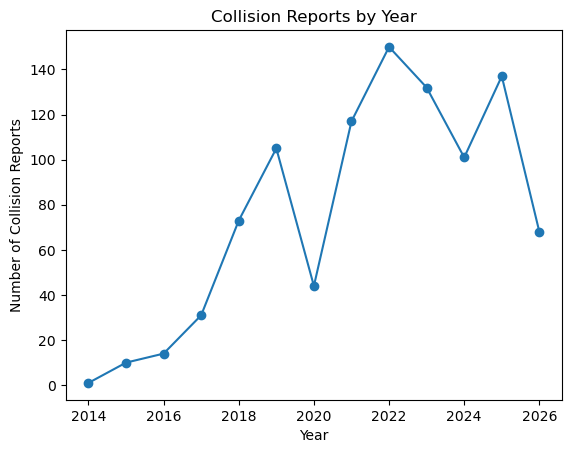

In [55]:
collision_by_year = collision_df['Year'].value_counts().sort_index()

collision_by_year.plot(kind='line', marker='o')

plt.title('Collision Reports by Year')
plt.xlabel('Year')
plt.ylabel('Number of Collision Reports')

plt.show()


Observation: Collision reports generally increased over the reporting period, although the number varies from year to year. The highest number of reports occurred in 2022, followed by another increase in 2025. These counts should be interpreted carefully because changes may reflect differences in testing activity and mileage, and the most recent year may contain incomplete data.

## Preparing Data for Modeling

In [56]:
disengagement_df['Risk_Event'] = 0
collision_df['Risk_Event'] = 1

In [57]:
print(disengagement_df['Risk_Event'].value_counts())
print(collision_df['Risk_Event'].value_counts())

Risk_Event
0    1773
Name: count, dtype: int64
Risk_Event
1    983
Name: count, dtype: int64


In [58]:
print("Disengagement Columns:")
print(disengagement_df.columns.tolist())

print("\nCollision Columns:")
print(collision_df.columns.tolist())

Disengagement Columns:
['Manufacturer', 'Permit Number', 'DATE', 'VIN NUMBER', 'VEHICLE IS CAPABLE OF OPERATING WITHOUT A DRIVER\n(Yes or No)', 'DRIVER PRESENT\n(Yes or No)', 'DISENGAGEMENT INITIATED BY\n(AV System, Test Driver, Remote Operator, or Passenger)', 'DISENGAGEMENT\nLOCATION\n(Interstate, Freeway, Highway, Rural Road, Street, or Parking Facility)', 'DESCRIPTION OF FACTS CAUSING DISENGAGEMENT', 'Month', 'Risk_Event']

Collision Columns:
['_Moving__V1_or_V2_or_Both_', '_Stopped__V1_or_V2_', '# of Vehicles involved', 'Backing', 'Broadside', 'City', 'Clear', 'Cloudy', 'Construction', 'County', 'Dark_No Street Lights', 'Dark_Street Lights', 'Day', 'Daylight', 'Dry', 'Dusk_Dawn', 'Entering_Traffic', 'First Street Name', 'First Street Suffix', 'Fog_Visability', 'Head On', 'Hit_Object', 'Injury', 'Involved', 'Lane_Change', 'Left_Turn_', 'Loose material', 'Merging', 'Month', 'Mud_Oil', 'No Unusual Conditions', 'Obstruction', 'Occurred @ Intersection', 'OtherCondition', 'OtherRoadCond

In [59]:
disengagement_df['Year'] = disengagement_df['DATE'].dt.year

disengagement_df['Year'].value_counts().sort_index()

Year
2023     316
2024    1457
Name: count, dtype: int64

In [60]:
disengagement_df['Month_Number'] = disengagement_df['DATE'].dt.month

disengagement_df['Month_Number'].value_counts().sort_index()

Month_Number
1     429
2     287
3     148
4     235
5     113
6      43
7      20
8      34
9      63
10     52
11     32
12    317
Name: count, dtype: int64

In [61]:
collision_df['Month'].value_counts(dropna=False)

Month
3                      101
10                      89
8                       88
2                       85
7                       85
1                       84
6                       80
9                       80
5                       76
4                       74
11                      74
12                      66
1900-01-06 00:00:00      1
Name: count, dtype: int64

In [62]:
collision_df.loc[collision_df['Month'].astype(str).str.contains('1900-01-06'),'Month'] = 6

In [63]:
collision_df['Month'] = pd.to_numeric(collision_df['Month'])
collision_df['Month'].value_counts().sort_index()

Month
1      84
2      85
3     101
4      74
5      76
6      81
7      85
8      88
9      80
10     89
11     74
12     66
Name: count, dtype: int64

In [64]:
disengagement_2024 = disengagement_df[disengagement_df['Year'] == 2024].copy()

collision_2024 = collision_df[collision_df['Year'] == 2024].copy()

print("2024 Disengagements:", len(disengagement_2024))
print("2024 Collisions:", len(collision_2024))

2024 Disengagements: 1457
2024 Collisions: 101


In [65]:
print("Disengagement Manufacturers:")
print(disengagement_2024['Manufacturer'].value_counts())

print("\nCollision Manufacturers:")
print(collision_2024['V1_Manufacturer'].value_counts())

Disengagement Manufacturers:
Manufacturer
Motional AD Inc.                                            298
Ghost Autonomy Inc.                                         265
Waymo LLC                                                   236
Apple Inc.                                                  191
IMAGRY                                                      120
aiMotive Inc.                                               116
NURO, INC.                                                   97
BOSCH                                                        68
Zoox, Inc.                                                   34
Valeo North America Inc.                                     12
Nissan North America. INC DBA NATC-SV                         8
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
PONY.AI, INC.                                                 3
Weride Corp                                                   3
Cruise LLC                                                    

In [66]:
disengagement_2024['Manufacturer_Clean'] = (disengagement_2024['Manufacturer'].str.strip().str.upper())
collision_2024['Manufacturer_Clean'] = (collision_2024['V1_Manufacturer'].str.strip().str.upper())
print(disengagement_2024['Manufacturer_Clean'].unique())
print()
print(collision_2024['Manufacturer_Clean'].unique())

['AIMOTIVE INC.' 'APPLE INC.' 'BOSCH' 'CRUISE LLC' 'GATIK AI, INC.'
 'GHOST AUTONOMY INC.' 'IMAGRY'
 'MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.'
 'MOTIONAL AD INC.' 'NISSAN NORTH AMERICA. INC DBA NATC-SV' 'NURO, INC.'
 'PONY.AI, INC.' 'VALEO NORTH AMERICA INC.' 'WAYMO LLC' 'WERIDE CORP'
 'ZOOX, INC.']

['ZOOX INC' 'GHOST AUTONOMY INC' 'NURO, INC' 'WERIDE CORP DBA WERIDE AI'
 'WAYMO LLC' 'APPLE INC' 'PONY.AI' 'WOVEN BY TOYOTA']


In [67]:
disengagement_2024['Manufacturer_Clean'] = disengagement_2024['Manufacturer_Clean'].replace({
    'APPLE INC.': 'APPLE INC',
    'GHOST AUTONOMY INC.': 'GHOST AUTONOMY INC',
    'NURO, INC.': 'NURO INC',
    'PONY.AI, INC.': 'PONY.AI',
    'ZOOX, INC.': 'ZOOX INC'
})

collision_2024['Manufacturer_Clean'] = collision_2024['Manufacturer_Clean'].replace({'NURO, INC': 'NURO INC'})

In [68]:
print(disengagement_2024['Manufacturer_Clean'].value_counts())
print()
print(collision_2024['Manufacturer_Clean'].value_counts())

Manufacturer_Clean
MOTIONAL AD INC.                                            298
GHOST AUTONOMY INC                                          265
WAYMO LLC                                                   236
APPLE INC                                                   191
IMAGRY                                                      120
AIMOTIVE INC.                                               116
NURO INC                                                     97
BOSCH                                                        68
ZOOX INC                                                     34
VALEO NORTH AMERICA INC.                                     12
NISSAN NORTH AMERICA. INC DBA NATC-SV                         8
MERCEDES-BENZ RESEARCH & DEVELOPMENT NORTH AMERICA, INC.      4
PONY.AI                                                       3
WERIDE CORP                                                   3
CRUISE LLC                                                    1
GATIK AI, INC.       

In [69]:
disengagement_model = disengagement_2024[['Manufacturer_Clean', 'Month_Number', 'Risk_Event']].copy()
collision_model = collision_2024[['Manufacturer_Clean', 'Month', 'Risk_Event']].copy()

In [70]:
collision_model = collision_model.rename(columns={'Month': 'Month_Number'})

In [71]:
print(disengagement_model.head())
print()
print(collision_model.head())

  Manufacturer_Clean  Month_Number  Risk_Event
0      AIMOTIVE INC.            11           0
1      AIMOTIVE INC.            11           0
2      AIMOTIVE INC.            11           0
3      AIMOTIVE INC.            10           0
4      AIMOTIVE INC.             9           0

            Manufacturer_Clean  Month_Number  Risk_Event
676                   ZOOX INC             1           1
677         GHOST AUTONOMY INC             1           1
678                   NURO INC             1           1
679  WERIDE CORP DBA WERIDE AI             1           1
680                  WAYMO LLC             1           1


In [72]:
model_df = pd.concat([disengagement_model, collision_model], ignore_index=True)
model_df.shape

(1558, 3)

In [73]:
model_df['Risk_Event'].value_counts()

Risk_Event
0    1457
1     101
Name: count, dtype: int64

In [74]:
X = model_df[['Manufacturer_Clean', 'Month_Number']]
y = model_df['Risk_Event']

print(X.head())
print()
print(y.head())

  Manufacturer_Clean  Month_Number
0      AIMOTIVE INC.            11
1      AIMOTIVE INC.            11
2      AIMOTIVE INC.            11
3      AIMOTIVE INC.            10
4      AIMOTIVE INC.             9

0    0
1    0
2    0
3    0
4    0
Name: Risk_Event, dtype: int64


In [75]:
from sklearn.model_selection import train_test_split

In [76]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())

print("\nTest target:")
print(y_test.value_counts())

Training data: (1246, 2)
Test data: (312, 2)

Training target:
Risk_Event
0    1165
1      81
Name: count, dtype: int64

Test target:
Risk_Event
0    292
1     20
Name: count, dtype: int64


In [77]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('manufacturer', OneHotEncoder(handle_unknown='ignore'), ['Manufacturer_Clean'])
    ],
    remainder='passthrough'
)

In [78]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


## Baseline Logistic Regression Model

In [79]:

model = Pipeline([('preprocessor', preprocessor),('classifier', LogisticRegression(class_weight='balanced',max_iter=1000,random_state=42))])

In [80]:
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('manufacturer', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
y_pred = model.predict(X_test)
print(y_pred[:20])

[0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 1]


## Model Evaluation

In [82]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7724358974358975
Precision: 0.2
Recall: 0.85
F1 Score: 0.3238095238095238


In [83]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[224  68]
 [  3  17]]


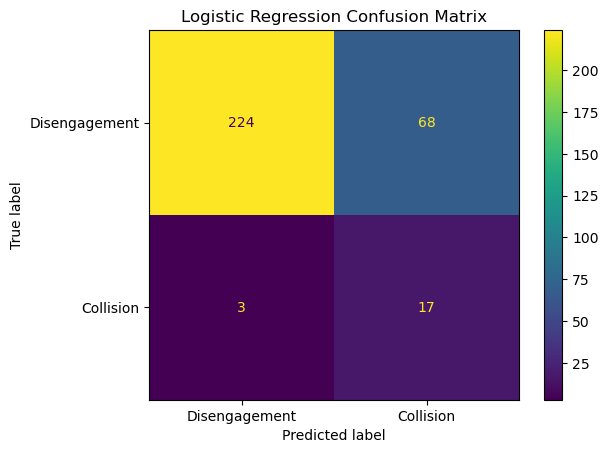

In [84]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Disengagement', 'Collision']).plot()

plt.title('Logistic Regression Confusion Matrix')
plt.show()

### Baseline Model Interpretation
The Logistic Regression model achieved an accuracy of 76.9%, recall of 85.0%, precision of 19.8%, and an F1-score of 32.1%. The model correctly identified 17 of the 20 collision events in the test data and missed 3. However, it also classified 69 disengagement events as collisions. The high recall is useful for this safety-focused problem because most collision events were identified, but the low precision shows that the baseline model produces many false positives. This suggests that additional features and more advanced models may improve the results.

In [85]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(model,X,y,cv=5,scoring='recall')
print("Recall scores:", cv_scores)
print("Average Recall:", cv_scores.mean())

Recall scores: [0.5  0.85 1.   0.95 1.  ]
Average Recall: 0.86


### Cross-Validation
The 5-fold cross-validation produced an average recall of 86%. This is close to the 85% recall obtained on the test set. However, recall varied across the folds, ranging from 45% to 100%. This variation may be related to the relatively small number of collision events in the dataset.

## Initial Findings

The exploratory analysis showed differences in disengagement and collision patterns across manufacturers. However, the raw number of events should not be used as a direct measure of safety because manufacturers have different levels of testing activity and autonomous mileage.

After accounting for autonomous mileage, disengagement rates also varied considerably across manufacturers. Manufacturers with very low testing mileage sometimes showed high disengagement rates, so these results need to be interpreted carefully.

In the collision data, rear-end collisions were the most common of the collision types examined. Most reported collisions did not include an injury, and more collision reports occurred while the vehicle was operating in autonomous mode than in conventional mode. These counts alone do not establish that autonomous operation is less safe because the amount of driving exposure in each mode is not available.

The baseline Logistic Regression model achieved 76.9% accuracy and identified 17 of the 20 collision events in the test set, resulting in 85% recall. However, precision was only 19.8%, indicating a relatively high number of false-positive collision predictions. The initial results suggest that the available features can identify some patterns associated with collision events, but additional features and model comparisons are needed before drawing stronger conclusions.

## Limitations

This analysis has several limitations. Collision events are treated as the higher-risk class and disengagement events as the comparison class. This provides a measurable target for the baseline classification model, but it should not be interpreted as a complete measure of autonomous vehicle safety.

The number of collision events is much smaller than the number of disengagement events, which creates class imbalance. In addition, manufacturers have different amounts of testing mileage and testing activity, so event counts should not be directly interpreted as differences in safety.

The baseline model also uses only manufacturer and month because these are common features that can be consistently compared across the two datasets. Additional environmental, roadway, vehicle, and event-related features may improve future models.

## Next Steps

The next phase of the project will compare the baseline Logistic Regression model with additional classification models, including Decision Tree, Random Forest, and Support Vector Machine (SVM). L1 regularization will also be explored for feature selection.

Additional features will be investigated to determine whether they can improve collision-event prediction while avoiding data leakage. Model performance will be compared using precision, recall, F1-score, confusion matrices, and cross-validation.

The final analysis will also focus on model interpretability to better understand which factors contribute to higher-risk autonomous vehicle safety events.